<a href="https://colab.research.google.com/github/avnee2607/AI-project/blob/main/Human_Activity_Recognition_CNN_LSTM_Fixed_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition using CNN-LSTM
## Bosch-inspired gesture-based human–machine interaction prototype

**Goal:** classify walking, jogging (running-like), sitting and standing from accelerometer and gyroscope time-series data.

**Environment:** Google Colab / Python. No physical sensor required for this prototype.

**Dataset:** WISDM Smartphone and Smartwatch Activity and Biometrics Dataset. Read the dataset's license/terms on the official UCI page before use. This notebook automatically extracts nested ZIP files, recursively finds raw phone accelerometer/gyroscope `.txt` files across different folder layouts, parses activity codes, and builds the sensor tables.

**Important limitation:** this is an academic prototype inspired by an industrial use case, not an official Bosch system and not safety-certified for machine control. Sensor streams are paired by subject/activity and row order, so results should be treated as a prototype unless timestamp alignment is independently validated.


## 1. Install and import libraries

In [ ]:
!pip -q install requests scikit-learn pandas matplotlib seaborn tensorflow

import os, re, zipfile, requests, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


## 2. Download and extract WISDM dataset
This cell downloads the archive if needed, then extracts it. It also supports a ZIP you already uploaded to `/content/wisdm_data/`.


In [ ]:
DATA_DIR = Path('/content/wisdm_data')
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = Path('/content/wisdm-dataset.zip')
DATA_URL = 'https://archive.ics.uci.edu/static/public/507/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset.zip'

if not ZIP_PATH.exists():
    existing_zips = list(DATA_DIR.glob('*.zip'))
    if existing_zips:
        ZIP_PATH = existing_zips[0]

if not ZIP_PATH.exists():
    try:
        print('Downloading dataset archive...')
        response = requests.get(DATA_URL, timeout=90)
        response.raise_for_status()
        ZIP_PATH.write_bytes(response.content)
        print('Downloaded:', round(ZIP_PATH.stat().st_size / (1024*1024), 1), 'MB')
    except Exception as e:
        raise RuntimeError(
            'Automatic download failed. Download the official WISDM ZIP from UCI, '
            'then upload it to /content/wisdm_data/ and rerun this cell.'
        ) from e

EXTRACT_DIR = DATA_DIR / 'extracted'
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

def safe_extract_zip(zip_file, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(zip_file, 'r') as zf:
        for member in zf.infolist():
            target = (destination / member.filename).resolve()
            if target != destination and destination not in target.parents:
                raise ValueError(f'Unsafe path in ZIP archive: {member.filename}')
        zf.extractall(destination)

safe_extract_zip(ZIP_PATH, EXTRACT_DIR)
print('Extracted outer archive:', ZIP_PATH.name)

# The official download can contain a second ZIP inside the first one.
for depth in range(3):
    nested_zips = [
        p for p in EXTRACT_DIR.rglob('*.zip')
        if p.is_file() and p.resolve() != ZIP_PATH.resolve()
    ]
    pending = []
    for nested in nested_zips:
        marker = nested.with_suffix(nested.suffix + '.extracted')
        if not marker.exists():
            pending.append((nested, marker))
    if not pending:
        break
    for nested, marker in pending:
        target_dir = nested.parent / (nested.stem + '_contents')
        target_dir.mkdir(parents=True, exist_ok=True)
        try:
            safe_extract_zip(nested, target_dir)
            marker.touch()
            print('Extracted nested archive:', nested.name, '->', target_dir)
        except zipfile.BadZipFile:
            print('Skipping invalid nested ZIP:', nested)


Downloaded: 295.9 MB
Extracted outer archive: wisdm-dataset.zip
Extracted nested archive: wisdm-dataset.zip -> /content/wisdm_data/extracted/wisdm-dataset_contents


## 3. Inspect the extracted files
The archive includes raw text files and may also include ARFF files. This project uses the raw phone `.txt` sensor files.


In [ ]:
all_files = [p for p in EXTRACT_DIR.rglob('*') if p.is_file() and not p.name.endswith('.extracted')]
print('Total extracted files:', len(all_files))
for p in all_files[:60]:
    print(p.relative_to(EXTRACT_DIR))

# Search recursively: do not assume a fixed folder nesting level.
def is_phone_sensor_file(path, sensor_name):
    low_path = str(path).lower().replace('\\', '/')
    name = path.name.lower()
    return (
        path.is_file()
        and path.suffix.lower() == '.txt'
        and sensor_name in name
        and 'watch' not in low_path
        and 'smartwatch' not in low_path
        and ('phone' in low_path or path.parent.name.lower() == sensor_name)
    )

accel_files = sorted([p for p in EXTRACT_DIR.rglob('*.txt') if is_phone_sensor_file(p, 'accel')])
gyro_files = sorted([p for p in EXTRACT_DIR.rglob('*.txt') if is_phone_sensor_file(p, 'gyro')])

# Fallback for files stored directly in folders named accel/gyro.
if not accel_files:
    accel_files = sorted([
        p for p in EXTRACT_DIR.rglob('*.txt')
        if p.is_file() and p.parent.name.lower() == 'accel'
        and 'watch' not in str(p).lower() and 'smartwatch' not in str(p).lower()
    ])
if not gyro_files:
    gyro_files = sorted([
        p for p in EXTRACT_DIR.rglob('*.txt')
        if p.is_file() and p.parent.name.lower() == 'gyro'
        and 'watch' not in str(p).lower() and 'smartwatch' not in str(p).lower()
    ])

print('\\nPhone accelerometer files found:', len(accel_files))
print('Phone gyroscope files found:', len(gyro_files))
if accel_files:
    print('Example accelerometer path:', accel_files[0])
if gyro_files:
    print('Example gyroscope path:', gyro_files[0])

if not accel_files or not gyro_files:
    raise FileNotFoundError(
        'Could not find both accelerometer and gyroscope .txt files even after nested ZIP extraction. '
        'Check the printed file list; the archive may have a different layout.'
    )


Total extracted files: 465
wisdm-dataset.zip
WISDM-dataset-description.pdf
wisdm-dataset_contents/wisdm-dataset/README.txt
wisdm-dataset_contents/wisdm-dataset/.activity_key.txt.swp
wisdm-dataset_contents/wisdm-dataset/activity_key.txt
wisdm-dataset_contents/wisdm-dataset/WISDM-dataset-description.pdf
wisdm-dataset_contents/wisdm-dataset/change_raw_act.pl
wisdm-dataset_contents/wisdm-dataset/raw/.DS_Store
wisdm-dataset_contents/wisdm-dataset/arffmagic-master/.DS_Store
wisdm-dataset_contents/wisdm-dataset/arffmagic-master/README.md
wisdm-dataset_contents/wisdm-dataset/arffmagic-master/Makefile
wisdm-dataset_contents/wisdm-dataset/arff_files/.DS_Store
wisdm-dataset_contents/wisdm-dataset/arff_files/phone/.DS_Store
wisdm-dataset_contents/wisdm-dataset/arff_files/watch/.DS_Store
wisdm-dataset_contents/wisdm-dataset/arff_files/watch/accel/data_1643_accel_watch.arff
wisdm-dataset_contents/wisdm-dataset/arff_files/watch/accel/data_1604_accel_watch.arff
wisdm-dataset_contents/wisdm-dataset/arf

## 4. Load raw sensor data
The raw files contain rows such as `1633,A,6947807196909246,-1.46,-6.27,0.72;`. The second field is an activity code, not a word like `walking`. This parser supports the WISDM codes A (walking), B (jogging), D (sitting), and E (standing), which should be verified against the included `activity_key.txt` for the downloaded dataset version.


In [ ]:
TARGET_ACTIVITIES = {
    'a': 'Walking', 'walking': 'Walking', 'walk': 'Walking',
    'b': 'Jogging', 'jogging': 'Jogging', 'jog': 'Jogging', 'running': 'Jogging',
    'd': 'Sitting', 'sitting': 'Sitting', 'sit': 'Sitting',
    'e': 'Standing', 'standing': 'Standing', 'stand': 'Standing'
}

def parse_wisdm_raw_file(path):
    rows = []
    with open(path, 'r', errors='ignore') as f:
        for line in f:
            line = line.strip().rstrip(';')
            if not line or line.lower().startswith(('user', '@relation', '@attribute', '@data')):
                continue
            parts = [x.strip() for x in line.split(',')]
            if len(parts) < 6:
                continue
            try:
                subject = str(parts[0])
                activity_raw = parts[1].lower()
                timestamp = float(parts[2])
                x, y, z = map(float, parts[3:6])
            except (ValueError, IndexError):
                continue
            if activity_raw in TARGET_ACTIVITIES:
                rows.append((subject, TARGET_ACTIVITIES[activity_raw], timestamp, x, y, z))
    return pd.DataFrame(rows, columns=['subject', 'activity', 'timestamp', 'x', 'y', 'z'])

# Use accel_files and gyro_files discovered in the previous cell.
accel_parts = [parse_wisdm_raw_file(p) for p in accel_files]
gyro_parts = [parse_wisdm_raw_file(p) for p in gyro_files]
accel_parts = [df for df in accel_parts if not df.empty]
gyro_parts = [df for df in gyro_parts if not df.empty]

if not accel_parts or not gyro_parts:
    # Show one raw line to make a format mismatch easy to diagnose.
    example_file = accel_files[0] if accel_files else gyro_files[0]
    with open(example_file, 'r', errors='ignore') as f:
        example_line = f.readline().strip()
    raise RuntimeError(
        'Raw files were found, but no rows matched the selected activity codes. '
        f'Example first line from {example_file.name}: {example_line!r}. '
        'Check activity_key.txt and update TARGET_ACTIVITIES if this dataset version uses different codes.'
    )

accel_df = pd.concat(accel_parts, ignore_index=True)
gyro_df = pd.concat(gyro_parts, ignore_index=True)
print('Accelerometer rows:', len(accel_df))
print('Gyroscope rows:', len(gyro_df))
print('Accelerometer activities:', accel_df['activity'].value_counts().to_dict())
print('Gyroscope activities:', gyro_df['activity'].value_counts().to_dict())
display(accel_df.head())
display(gyro_df.head())


Accelerometer rows: 1082422
Gyroscope rows: 808892
Accelerometer activities: {'Walking': 279817, 'Standing': 269604, 'Jogging': 268409, 'Sitting': 264592}
Gyroscope activities: {'Walking': 203919, 'Sitting': 202370, 'Standing': 202351, 'Jogging': 200252}


,subject,activity,timestamp,x,y,z
0,1600,Walking,2.522077e+14,-0.364761,8.793503,1.055084
1,1600,Walking,2.522077e+14,-0.879730,9.768784,1.016998
2,1600,Walking,2.522078e+14,2.001495,11.109070,2.619156
3,1600,Walking,2.522078e+14,0.450623,12.651642,0.184555
4,1600,Walking,2.522079e+14,-2.164352,13.928436,-4.422485


,subject,activity,timestamp,x,y,z
0,1600,Walking,2.522079e+14,-0.853210,0.297226,0.890182
1,1600,Walking,2.522080e+14,-0.875137,0.015472,0.162231
2,1600,Walking,2.522080e+14,-0.720169,0.388489,-0.284012
3,1600,Walking,2.522081e+14,-0.571640,1.227402,-0.241669
4,1600,Walking,2.522081e+14,-0.380493,1.202835,-0.213135


## 5. Pair accelerometer and gyroscope readings
The model uses six features per time step: accelerometer X/Y/Z and gyroscope X/Y/Z. This implementation matches each subject/activity stream and pairs rows in timestamp-sorted order, truncating to the shorter stream. It does **not** claim exact timestamp synchronization; that is a limitation of this prototype.


In [ ]:
def pair_sensor_streams(accel, gyro):
    required = {'subject', 'activity', 'timestamp', 'x', 'y', 'z'}
    if accel.empty or gyro.empty:
        raise ValueError('Accelerometer or gyroscope table is empty. Run the raw-data loading cell successfully first.')
    if not required.issubset(accel.columns) or not required.issubset(gyro.columns):
        raise ValueError(f'Both sensor tables must contain these columns: {sorted(required)}')

    key_cols = ['subject', 'activity']
    accel_keys = set(map(tuple, accel[key_cols].drop_duplicates().to_numpy()))
    gyro_keys = set(map(tuple, gyro[key_cols].drop_duplicates().to_numpy()))
    common = accel_keys & gyro_keys
    print('Matching subject/activity streams:', len(common))
    out = []

    for subject, activity in sorted(common, key=lambda x: (str(x[0]), x[1])):
        a = accel[(accel.subject == subject) & (accel.activity == activity)].sort_values('timestamp').reset_index(drop=True)
        g = gyro[(gyro.subject == subject) & (gyro.activity == activity)].sort_values('timestamp').reset_index(drop=True)
        n = min(len(a), len(g))
        if n < 100:
            continue
        part = pd.DataFrame({
            'subject': str(subject), 'activity': activity,
            'timestamp': a['timestamp'].iloc[:n].to_numpy(),
            'acc_x': a['x'].iloc[:n].to_numpy(),
            'acc_y': a['y'].iloc[:n].to_numpy(),
            'acc_z': a['z'].iloc[:n].to_numpy(),
            'gyro_x': g['x'].iloc[:n].to_numpy(),
            'gyro_y': g['y'].iloc[:n].to_numpy(),
            'gyro_z': g['z'].iloc[:n].to_numpy()
        })
        out.append(part)

    if not out:
        raise RuntimeError(
            'No paired streams with at least 100 rows were created. '
            'Check activity labels and whether both sensors contain the same subjects/activities.'
        )
    result = pd.concat(out, ignore_index=True)
    if result.empty or not {'subject', 'activity', 'acc_x', 'gyro_x'}.issubset(result.columns):
        raise RuntimeError('Paired sensor table is empty or missing expected columns.')
    return result

sensor_df = pair_sensor_streams(accel_df, gyro_df)
print('Paired sensor table shape:', sensor_df.shape)
print('Paired activity counts:', sensor_df['activity'].value_counts().to_dict())
display(sensor_df.head())


Matching subject/activity streams: 202
Paired sensor table shape: (808889, 9)
Paired activity counts: {'Walking': 203919, 'Sitting': 202369, 'Standing': 202350, 'Jogging': 200251}


,subject,activity,timestamp,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,1600,Jogging,2.519876e+14,1.375549,15.375046,2.971619,0.410278,1.710571,0.504745
1,1600,Jogging,2.519877e+14,-3.934433,17.538788,2.110016,-0.256134,0.380859,-0.295776
2,1600,Jogging,2.519877e+14,-0.087738,12.791565,-1.454102,-0.691132,-0.299866,0.030258
3,1600,Jogging,2.519878e+14,2.038742,3.077148,-1.053726,0.525040,-0.006882,0.728622
4,1600,Jogging,2.519878e+14,-2.558472,-2.738678,-2.098511,-1.007584,-0.192322,-1.147400


## 6. Visualize sensor readings


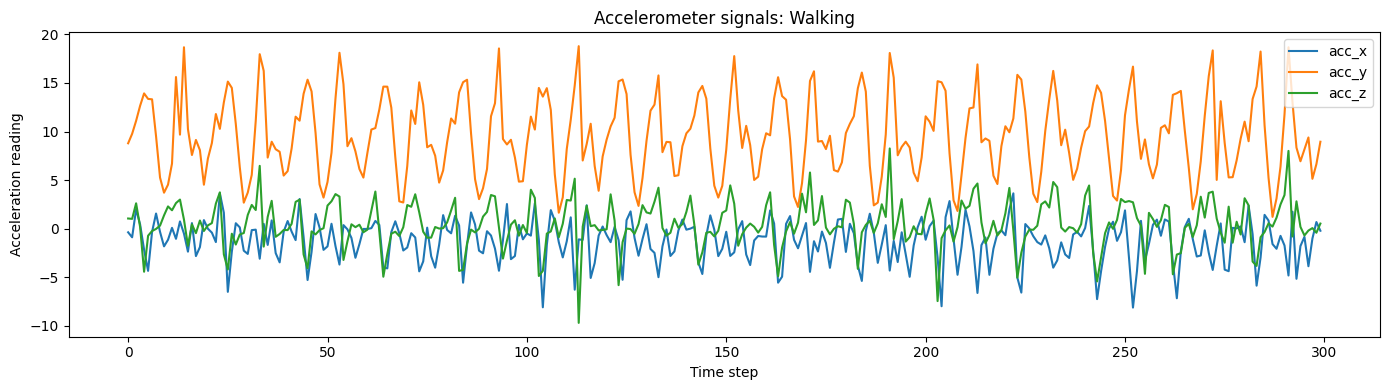

In [ ]:
example_activity = 'Walking'
example = sensor_df[sensor_df['activity'] == example_activity].head(300)
if example.empty:
    print(f'No rows available for {example_activity}. Available classes:', sorted(sensor_df['activity'].unique()))
else:
    plt.figure(figsize=(14, 4))
    for col in ['acc_x', 'acc_y', 'acc_z']:
        plt.plot(example[col].to_numpy(), label=col)
    plt.title(f'Accelerometer signals: {example_activity}')
    plt.xlabel('Time step')
    plt.ylabel('Acceleration reading')
    plt.legend()
    plt.tight_layout()
    plt.show()


## 7. Create labeled windows
Each window contains 100 time steps (about five seconds at 20 Hz) and six sensor channels. Windows are built inside each subject/activity stream so a window does not cross a label boundary.

In [ ]:
FEATURES = ['acc_x','acc_y','acc_z','gyro_x','gyro_y','gyro_z']
WINDOW_SIZE = 100
STEP_SIZE = 50

X_list, y_list, groups = [], [], []
for (subject, activity), group in sensor_df.groupby(['subject','activity'], sort=False):
    values = group[FEATURES].replace([np.inf, -np.inf], np.nan).dropna().to_numpy(dtype=np.float32)
    for start in range(0, len(values) - WINDOW_SIZE + 1, STEP_SIZE):
        X_list.append(values[start:start + WINDOW_SIZE])
        y_list.append(activity)
        groups.append(str(subject))

X = np.asarray(X_list, dtype=np.float32)
y_text = np.asarray(y_list)
groups = np.asarray(groups)
print('X shape:', X.shape, '(windows, time steps, channels)')
print('Class counts:', pd.Series(y_text).value_counts().to_dict())
if len(X) == 0 or len(np.unique(y_text)) < 2:
    raise RuntimeError('Not enough labeled windows were created. Verify the raw file format and target activity labels.')

X shape: (15894, 100, 6) (windows, time steps, channels)
Class counts: {'Walking': 4008, 'Sitting': 3975, 'Standing': 3975, 'Jogging': 3936}


## 8. Split by participant and normalize
Participant-level splitting helps test whether the model generalizes to people it did not train on. Normalization statistics are fitted on training data only.

In [ ]:
# Try several participant-level splits to include all available classes in both sets.
splitter = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=SEED)
split_found = False
all_classes = set(y_text)

for train_candidate, test_candidate in splitter.split(X, y_text, groups):
    if set(y_text[train_candidate]) == all_classes and set(y_text[test_candidate]) == all_classes:
        train_idx, test_idx = train_candidate, test_candidate
        split_found = True
        break

if not split_found:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train_idx, test_idx = next(splitter.split(X, y_text, groups))
    if set(y_text[train_idx]) != all_classes:
        raise RuntimeError(
            'The participant-level split cannot put every activity class in training. '
            'Check how many participants provide each activity before changing the split.'
        )

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train_text, y_test_text = y_text[train_idx], y_text[test_idx]

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
missing_test_classes = sorted(set(y_test_text) - set(label_encoder.classes_))
y_test = label_encoder.transform(y_test_text)

scaler = StandardScaler()
scaler.fit(X_train_raw.reshape(-1, X_train_raw.shape[-1]))
X_train = scaler.transform(X_train_raw.reshape(-1, X_train_raw.shape[-1])).reshape(X_train_raw.shape).astype(np.float32)
X_test = scaler.transform(X_test_raw.reshape(-1, X_test_raw.shape[-1])).reshape(X_test_raw.shape).astype(np.float32)
print('Classes:', list(label_encoder.classes_))
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train subjects:', len(np.unique(groups[train_idx])), 'Test subjects:', len(np.unique(groups[test_idx])))
print('Training class counts:', pd.Series(y_train_text).value_counts().to_dict())
print('Test class counts:', pd.Series(y_test_text).value_counts().to_dict())
if missing_test_classes:
    print('Note: these classes are absent from the held-out test split:', missing_test_classes)


Classes: [np.str_('Jogging'), np.str_('Sitting'), np.str_('Standing'), np.str_('Walking')]
Train: (12518, 100, 6) Test: (3376, 100, 6)
Train subjects: 40 Test subjects: 11
Training class counts: {'Walking': 3164, 'Sitting': 3131, 'Standing': 3131, 'Jogging': 3092}
Test class counts: {'Jogging': 844, 'Sitting': 844, 'Standing': 844, 'Walking': 844}


## 9. Build the CNN-LSTM model

In [ ]:
num_classes = len(label_encoder.classes_)
model = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, len(FEATURES))),
    layers.Conv1D(64, kernel_size=5, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    layers.LSTM(64),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 64)        │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,572 (193.64 KB)

 Trainable params: 49,572 (193.64 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Train the model

In [ ]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.8150 - loss: 0.4677 - val_accuracy: 0.8530 - val_loss: 0.3849
Epoch 2/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9413 - loss: 0.1732 - val_accuracy: 0.8918 - val_loss: 0.3918
Epoch 3/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9633 - loss: 0.1096 - val_accuracy: 0.7843 - val_loss: 0.7225
Epoch 4/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9714 - loss: 0.1071 - val_accuracy: 0.8642 - val_loss: 0.4530
Epoch 5/20
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9778 - loss: 0.0752 - val_accuracy: 0.8359 - val_loss: 0.6076


## 11. Plot training history

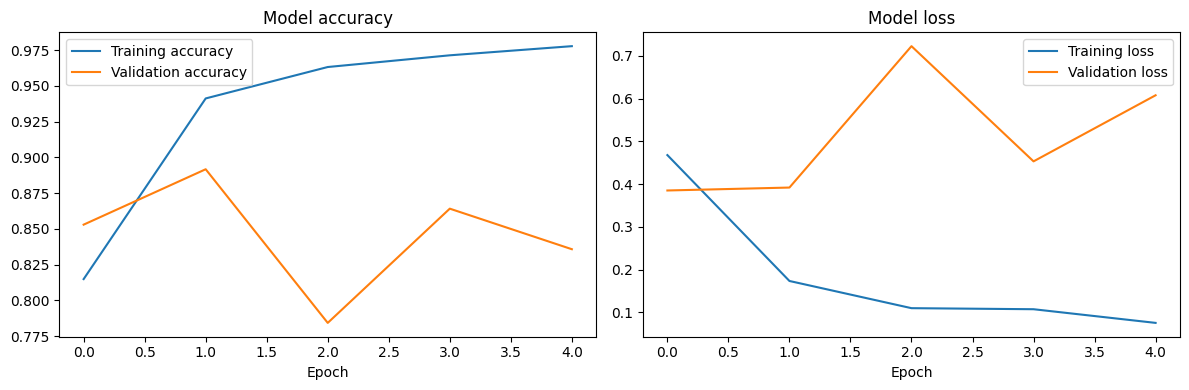

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='Training accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Model accuracy'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['loss'], label='Training loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Model loss'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

## 12. Evaluate with accuracy, precision, recall, F1-score and confusion matrix

Test accuracy: 0.8421

Classification report:

              precision    recall  f1-score   support

     Jogging       0.74      0.96      0.83       844
     Sitting       0.89      0.86      0.87       844
    Standing       0.87      0.89      0.88       844
     Walking       0.94      0.66      0.77       844

    accuracy                           0.84      3376
   macro avg       0.86      0.84      0.84      3376
weighted avg       0.86      0.84      0.84      3376



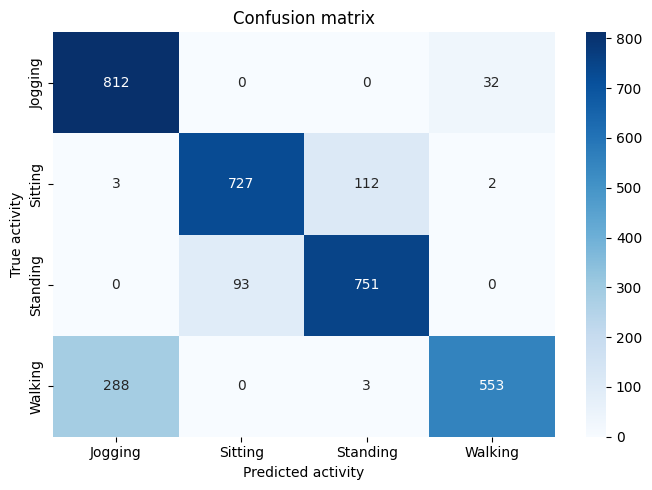

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, verbose=0)
y_pred = probabilities.argmax(axis=1)
print(f'Test accuracy: {test_accuracy:.4f}')
print('\nClassification report:\n')
print(classification_report(y_test, y_pred, labels=np.arange(num_classes), target_names=label_encoder.classes_, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted activity'); plt.ylabel('True activity'); plt.title('Confusion matrix')
plt.tight_layout(); plt.show()

## 13. Demo: predict activity from a held-out sensor window
This demonstrates the complete inference path using a real test window. It is not live sensor input.

In [ ]:
def predict_activity(window):
    window = np.asarray(window, dtype=np.float32)
    if window.shape != (WINDOW_SIZE, len(FEATURES)):
        raise ValueError(f'Expected shape {(WINDOW_SIZE, len(FEATURES))}, received {window.shape}')
    normalized = scaler.transform(window).reshape(1, WINDOW_SIZE, len(FEATURES)).astype(np.float32)
    probs = model.predict(normalized, verbose=0)[0]
    best = int(np.argmax(probs))
    return label_encoder.classes_[best], float(probs[best]), dict(zip(label_encoder.classes_, probs.tolist()))

sample_idx = 0
activity, confidence, all_probabilities = predict_activity(X_test_raw[sample_idx])
print('Predicted activity:', activity)
print('Model confidence:', f'{confidence:.1%}')
print('Probabilities:')
for name, value in sorted(all_probabilities.items(), key=lambda item: item[1], reverse=True):
    print(f'  {name}: {value:.1%}')
print('Actual activity:', y_test_text[sample_idx])

Predicted activity: Walking
Model confidence: 54.9%
Probabilities:
  Walking: 54.9%
  Jogging: 44.9%
  Sitting: 0.2%
  Standing: 0.1%
Actual activity: Jogging


## 14. Save model and preprocessing objects
Download these files after training if you want to reuse the model in a separate demo.

In [ ]:
import pickle
model.save('/content/cnn_lstm_har_model.keras')
with open('/content/har_preprocessing.pkl', 'wb') as f:
    pickle.dump({'scaler': scaler, 'label_encoder': label_encoder, 'features': FEATURES,
                 'window_size': WINDOW_SIZE, 'step_size': STEP_SIZE}, f)
print('Saved model and preprocessing objects to /content')

# Optional: download model from Colab
from google.colab import files
files.download('/content/cnn_lstm_har_model.keras')
files.download('/content/har_preprocessing.pkl')

Saved model and preprocessing objects to /content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Project conclusion template
After running the notebook, replace the blanks with your actual measured results:

- Dataset used: WISDM smartphone sensor data.
- Activities classified: the classes successfully loaded by the notebook.
- Input: 100 time steps × 6 sensor channels per window.
- Model: 1D CNN followed by LSTM and dense classification layers.
- Held-out participant test accuracy: ____.
- Macro F1-score: ____.
- Main limitation: predictions are based on the available dataset and are not validated for industrial safety-critical control.

**Do not invent or pre-fill accuracy numbers. Use the results printed by your run.**